# Lab L1-4：斷線不怕、主管點得到（D1-4）

**需求單 #D1-4**（虛構公司：曜嶼電子，資訊部）：Colab 斷線害我們白訓練一天；主管要一個自己點得到的展示。

| Part | 做什麼 | 驗收 |
|---|---|---|
| A | 檢查點存到 Google Drive，中斷後接著訓練 | 接續時從「上次存的 epoch + 1」開始 |
| B | 從 Hub 載入模型，量 fp32 與 fp16 的 VRAM | 實測和「參數 × 位元組」估算接近 |
| C | 樣本網格＋ Gradio 網頁 | 上傳圖片 → 前 3 名類別 |

> 狀態：本筆記本尚未在 Colab T4 實跑（見 `research/lab-runs.md`）。

In [35]:
# 第 1 格：環境
%pip install -q -U transformers gradio
import torch, os, gc, platform
print("torch", torch.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
torch.manual_seed(0)

torch 2.14.1+cu130 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 14.9 / 15.6 GB


## Part A：檢查點存到 Google Drive
第一次會跳出授權視窗。沒有 Drive（或不想授權）：自動改存在 `/content/ckpt`（斷線就會消失，只能練習流程）。

In [36]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT_DIR = "/content/drive/MyDrive/GAI/ckpt"
except Exception as e:
    print("沒有掛載 Drive：", e)
    CKPT_DIR = "ckpt"
os.makedirs(CKPT_DIR, exist_ok=True)
CKPT = os.path.join(CKPT_DIR, "cifar_cnn_ckpt.pt")
print("檢查點路徑：", CKPT)

沒有掛載 Drive： User cancelled dfs_ephemeral authorization
檢查點路徑： ckpt/cifar_cnn_ckpt.pt


In [37]:
# D1-3 的模型與資料（每個 deck 自帶一份，不從別的 Lab import）
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.25),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Dropout(0.25))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 6 * 6, 512), nn.ReLU(), nn.Dropout(0.5), nn.Linear(512, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

tf = transforms.ToTensor()
train_ds = datasets.CIFAR10("data/download", train=True, download=True, transform=tf)
test_ds = datasets.CIFAR10("data/download", train=False, download=True, transform=tf)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=256, num_workers=2)
CLASSES = train_ds.classes
loss_fn = nn.CrossEntropyLoss()

def train_one_epoch(model, optimizer):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    return loss.item()

@torch.no_grad()
def evaluate(model):
    model.eval(); correct = 0
    for x, y in test_loader:
        correct += (model(x.to(device)).argmax(1) == y.to(device)).sum().item()
    return correct / len(test_ds)

100%|██████████| 170M/170M [31:20<00:00, 90.7kB/s] 


### 可以接續的訓練迴圈
檢查點要存三樣東西：**模型權重、優化器狀態、epoch**。只存模型權重的話，Adam 的動量會歸零，epoch 也不知道從哪裡接。

示範「斷線」：`STOP_AFTER = 2` 會在第 2 個 epoch 存檔後停下。接著把它改成 `None` 再執行同一格，看它從第 3 個 epoch 接著跑。
真的斷線也一樣：重新連線後從第 1 格依序執行到這一格。

In [38]:
EPOCHS = 4
STOP_AFTER = 2   # 第一次執行：2；第二次執行：改成 None

model = Net().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
start_epoch, history = 1, []

if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device)
    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    start_epoch, history = ck["epoch"] + 1, ck["history"]
    print(f"找到檢查點：從 epoch {start_epoch} 接著訓練")

for epoch in range(start_epoch, EPOCHS + 1):
    last_loss = train_one_epoch(model, optimizer)
    acc = evaluate(model)
    history.append([epoch, last_loss, acc])
    torch.save({"epoch": epoch, "model": model.state_dict(), "optimizer": optimizer.state_dict(), "history": history}, CKPT)
    print(f"epoch {epoch}  test acc {acc:.3f}  → 已存 {CKPT}")
    if STOP_AFTER is not None and epoch >= STOP_AFTER:
        print("（模擬斷線：停在這裡。把 STOP_AFTER 改成 None 再執行這一格）")
        break

epoch 1  test acc 0.528  → 已存 ckpt/cifar_cnn_ckpt.pt
epoch 2  test acc 0.611  → 已存 ckpt/cifar_cnn_ckpt.pt
（模擬斷線：停在這裡。把 STOP_AFTER 改成 None 再執行這一格）


重新開始一次乾淨的練習：刪掉檢查點。

In [39]:
# os.remove(CKPT)   # 需要時才取消註解

## Part B：Hugging Face Hub 與 VRAM
### 模型倉庫裡有什麼？

In [40]:
from huggingface_hub import list_repo_files, model_info
REPO = "Qwen/Qwen2.5-0.5B-Instruct"
for f in list_repo_files(REPO):
    print(" ", f)
card = model_info(REPO).card_data
print("license:", card.get("license") if card else "（模型卡沒有填）")

  .gitattributes
  LICENSE
  README.md
  config.json
  generation_config.json
  merges.txt
  model.safetensors
  tokenizer.json
  tokenizer_config.json
  vocab.json
license: apache-2.0


### 先估算，再實測
權重的記憶體 ≈ 參數量 × 每個參數的位元組（fp32 = 4，fp16 = 2）。先在投影片的練習頁寫下估算，再執行。

In [41]:
from transformers import AutoModelForCausalLM

def measure(dtype):
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    m = AutoModelForCausalLM.from_pretrained(REPO, dtype=dtype).to("cuda")
    n = sum(p.numel() for p in m.parameters())
    peak = torch.cuda.max_memory_allocated() / 1e9
    del m; gc.collect(); torch.cuda.empty_cache()
    return n, peak

if device == "cuda":
    rows = []
    for name, dtype, nbytes in [("fp32", torch.float32, 4), ("fp16", torch.float16, 2)]:
        n, peak = measure(dtype)
        est = n * nbytes / 1e9
        rows.append((name, n, est, peak))
        print(f"{name}: 參數 {n/1e6:.0f}M | 估算 {est:.2f} GB | 實測峰值 {peak:.2f} GB")
else:
    print("沒有 GPU：只能算估算值（參數量 × 位元組），無法實測 VRAM")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

[ERROR] `cache` is part of Qwen2Model.forward's signature, but not documented. Make sure to add it to the docstring of the function in /usr/local/lib/python3.13/dist-packages/transformers/models/qwen2/modeling_qwen2.py.
[ERROR] `cache` is part of Qwen2ForCausalLM.forward's signature, but not documented. Make sure to add it to the docstring of the function in /usr/local/lib/python3.13/dist-packages/transformers/models/qwen2/modeling_qwen2.py.


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

fp32: 參數 494M | 估算 1.98 GB | 實測峰值 2.17 GB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

fp16: 參數 494M | 估算 0.99 GB | 實測峰值 1.19 GB


## Part C：樣本網格與 Gradio 網頁
主管看不懂數字，但看得懂一排圖。之後每一個生成模型都用網格來判斷好壞。

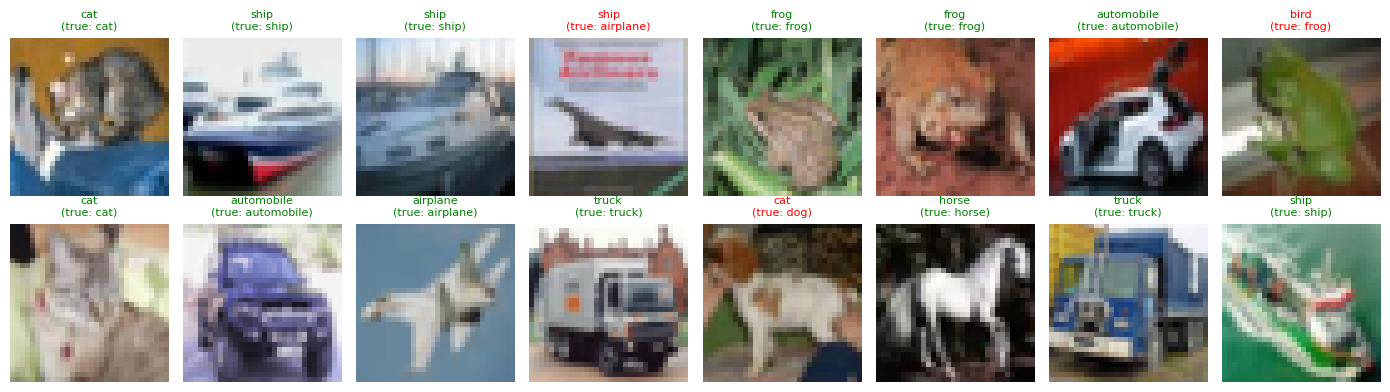

In [42]:
import matplotlib.pyplot as plt
x, y = next(iter(test_loader))
with torch.no_grad():
    model.eval(); pred = model(x[:16].to(device)).argmax(1).cpu()
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, t, p in zip(axes.flat, x[:16], y[:16], pred):
    ax.imshow(img.permute(1, 2, 0))            # CHW → HWC 給 matplotlib
    ax.set_title(f"{CLASSES[p]}\n(true: {CLASSES[t]})", fontsize=8, color="green" if p == t else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

In [43]:
import gradio as gr

def predict(img):
    x = tf(img.convert("RGB").resize((32, 32))).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(x), dim=1)[0].cpu()
    return {CLASSES[i]: float(p[i]) for i in range(10)}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="上傳一張圖"),
    outputs=gr.Label(num_top_classes=3, label="前 3 名"),
    title="曜嶼電子（虛構）分類器展示",
    description="CIFAR-10 代替公司的瑕疵影像。模型：D1-3 移植的 CNN。",
)
demo.launch(share=True)   # share=True 產生一個暫時的公開網址（有效期限依 Gradio 版本，見官方文件）

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cb6a2b77dce8760cbf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
